# Forecasting Brent Crude Volatility and Backtesting Value-at-Risk

## Executive Summary

This project forecasts the volatility of Brent crude oil futures (`BZ=F`, January 2010 to October 2026) and tests whether better volatility forecasts produce a more reliable Value-at-Risk (VaR) estimate. Models were trained on 2010–2021 and judged on 1,195 unseen trading days from 2022 onwards.

**Key findings**
- **Brent's volatility is not constant.** Calm and turbulent periods cluster, and daily returns have fat tails (excess kurtosis ≈ 14.55) and a negative skew (≈ -0.95).
- **GARCH(1,1) with Student-t errors was the most accurate model.** It beat the best simple baseline (the 21-day rolling volatility) by about 5.7% on RMSE and 2.3% on MAE. The random forest did not beat it, mainly because trees cannot predict beyond the range of volatility they saw in training.
- **GARCH also gave the most reliable VaR.** At 95% confidence, a well-calibrated model should be breached on about 60 of the 1,195 test days. GARCH was breached on 61 (Kupiec p = 0.87). The baseline and random forest were each breached on 73 (p ≈ 0.09), which suggests they understate risk, though not by enough to be formally rejected.
- **Breaches did not show clear clustering.** The chance of a breach after a breach was 6.6%, against 5.0% after a day with no breach, but the first figure rests on only 4 events.
- **Volatility is asymmetric.** Volatility is about 14% higher after a big fall than after a big rise (the leverage effect), which standard GARCH cannot capture.
- **Next-month outlook.** Refitted on the full history, GARCH forecasts about 2.3% volatility on an average day (36.7% annualised, below the 44% long-run level), with a one-month price-change standard deviation of about 10.6%. This measures the size of likely moves, not their direction.

**Limitations**
- The price series is a continuous front-month contract, so it contains rollover jumps.
- The VaR applies a 5-day volatility forecast to a 1-day loss and assumes normal returns.
- The 21-day forecast has not been backtested.


## 1. Project Overview

Oil prices do not move by the same amount every day. Some periods are calm and others are turbulent, and the size of the daily swings (the **volatility**) changes over time. Traders and risk managers need to know how large those swings are likely to be, because it determines how much money could be lost on a bad day. <br>

This project asks two questions:
1. **Can the volatility of Brent crude oil over the next five trading days be forecast, and which method does it best?**
2. **Does a better volatility forecast produce a more reliable estimate of the amount that could be lost in a day?** <br>

That loss estimate is called **Value-at-Risk (VaR)**: the amount that should only be exceeded on about 1 day in 20 (for a 95% confidence level).

**The Data** <br>
The project uses daily closing prices for **Brent crude oil futures** (Yahoo Finance ticker `BZ=F`) from January 2010 to 9 October 2026, about 4,200 trading days. A futures contract is an agreement to buy or sell oil at a fixed price on a future date. The series used is a continuous front-month series, which means the price jumps when it moves from one contract to the next, a limitation discussed at the end.

**The Approach** <br>
The analysis follows the stages a risk analyst would use:
1. **Prepare and explore the data.** Convert prices into daily returns and examine how volatility behaves over time.
2. **Set up a fair test.** Build features and a target, then split the data by date so the models learn from 2010 to 2021 and are judged on 2022 onwards, which they never see.
3. **Set the benchmark.** Simple rules, such as "next week will be as volatile as the last month", show what a more complex model has to beat.
4. **Build two models.** GARCH, the standard finance model for volatility, and a random forest, a machine learning method.
5. **Convert forecasts into VaR and backtest.** Count how often actual losses exceeded each model's estimate, and test whether that count is statistically acceptable.
6. **Apply the model.** Use it to forecast the next month's volatility.

**How Accuracy is Judged** <br>
- **RMSE and MAE** measure how far forecasts are from what actually happened (lower is better).
- **Breach rate and the Kupiec test** measure whether the VaR estimate is exceeded about as often as it should be.

*Tools* <br>
Python (`pandas`, `numpy`), `yfinance` for the data, `arch` for GARCH, `scikit-learn` for the random forest, and `scipy` for the statistical tests.


## 2. Importing the Data

This section is used to import the most up-to-date data from a library named `yfinance` which is an open-source library that accesses data from Yahoo Finance and allows the user to import that data into a dataframe. <br><br>
Once the data has been imported into a dataframe, we can create series to use the data that we need for this project. In this case the two new series will be:
1. `prices` - which stores the official end-of-day price.
2. `returns` - which stores the log of the price ratio between the price today and the price yesterday.

These series set up the exploratory analysis in the next section, which looks at how Brent behaves over time. That behaviour motivates the models we build later.

In [1]:
# Install the necessary libraries
!pip install yfinance arch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 12.4 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Import the data for Brent crude oil since 01/01/2010
df = yf.download("BZ=F", start="2010-01-01", end="2026-10-10", auto_adjust=True)
print()
print(df.head())
df.columns = df.columns.get_level_values(0) # Keep the column names of the first index value

# Create a new dataframe in a variable which only includes prices at close of each day
prices = df['Close'].dropna()

# Create a new dataframe in a variable which works out the log of the price ratio between the closing price for day n and day n-1
returns = np.log(prices / prices.shift(1)).dropna()

# prices.to_csv('brent_prices.csv)    for when it comes to writing a report / readme

print()
print(df.index.min())
print(df.index.max())
print(len(prices))
print(returns.abs().sort_values().tail(5))

[*********************100%***********************]  1 of 1 completed


Price           Close       High        Low       Open Volume
Ticker           BZ=F       BZ=F       BZ=F       BZ=F   BZ=F
Date                                                         
2010-01-04  80.120003  79.820000  80.120003  80.120003     97
2010-01-05  80.589996  80.260002  80.589996  80.589996     97
2010-01-06  81.889999  81.699997  80.129997  81.129997      7
2010-01-07  81.510002  81.510002  81.629997  81.510002      7
2010-01-08  81.370003  81.529999  81.089996  81.370003      7

2010-01-04 00:00:00
2026-10-09 00:00:00
4187
Date
2020-03-18    0.143878
2026-04-01    0.156943
2020-04-02    0.190774
2020-03-09    0.275751
2020-04-21    0.279761
Name: Close, dtype: float64


## 3. Exploring the data

### 3.1 Price, Returns and Volatility Over Time

The simplest way to understand the two new series (`prices` and `returns`) is to plot three graphs.

1. **Closing price against time.** A simple line chart of the closing price for every trading day in the dataset (January 2010 to the present). This shows the long-run story: the 2011-2014 plateau, the 2014-2016 collapse, the 2020 crash and the spikes in 2022 and 2026.

2. **Daily log returns.** The log return for each day is calculated relative to the previous day's close. Log returns can be added together across multiple days to work out whether the price has moved up or down overall. Spikes in this graph show the biggest price changes and roughly when they occurred. The band is thin in calm periods and thick in turbulent ones.

3. **21-day rolling volatility, annualised.** Volatility here is the standard deviation of daily log returns over a sliding window of 21 trading days (about one month). Multiplying by the square root of 252 (the approximate number of trading days in a year) converts it to an annual figure, so it can be compared with volatility numbers quoted in the market. For example, 0.30 means the price is moving at an annualised rate of about 30%.


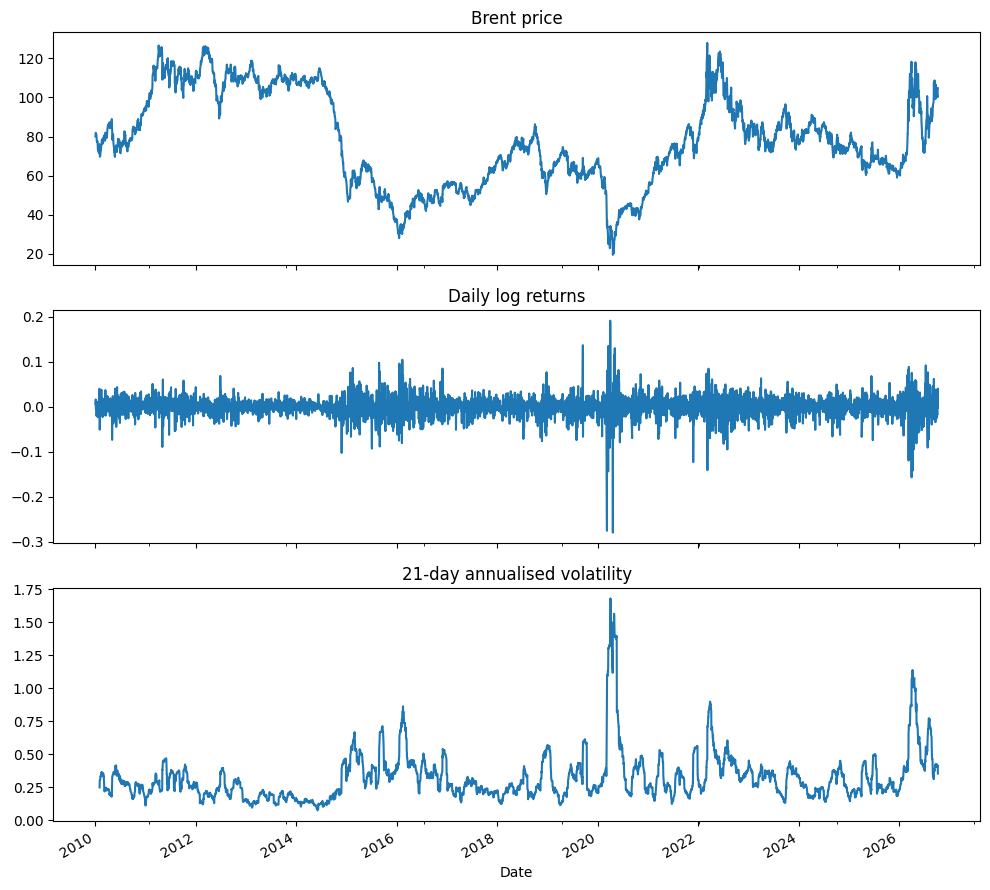

In [3]:
Whafig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Plot showing the closing price of Brent since 2010 to present
prices.plot(ax=ax[0], title="Brent price")

# Plot the returns column to show daily log returns
returns.plot(ax=ax[1], title="Daily log returns")

# Plot 21-day rolling volatility of Brent daily log returns, annualised
returns.rolling(21).std().mul(np.sqrt(252)).plot(ax=ax[2], title="21-day annualised volatility")
plt.tight_layout()
plt.show()

**What the charts show**

Taken together, the charts show that Brent's volatility is **not constant**. Calm and turbulent periods come in clusters: volatility is low through 2012-2014, rises sharply from late 2014, peaks at more than 150% annualised in spring 2020 and spikes again in 2022 and 2026. This is known as *volatility clustering*.
<br>
A simple risk model assumes one fixed level of volatility for all time. The clustering above shows that assumption is wrong, and it means recent volatility is a useful clue about near-future volatility.

### 3.2 Log returns vs normal distribution

Many standard risk models assume daily returns follow a normal (bell curve) distribution. Before relying on that assumption, we need to test it. The histogram below compares the actual distribution of Brent log returns with a normal curve that has the same mean and standard deviation. We also calculate two summary statistics:

**Skewness**: whether large moves are more common in one direction (0 means symmetric).

**Excess kurtosis**: how heavy the tails are compared with a normal distribution (0 means normal tails).

If returns show fat tails, extreme moves happen more often than a normal model predicts. That would justify using a Student-t distribution for the GARCH model, and would warn us that a normal-based VaR may understate risk.

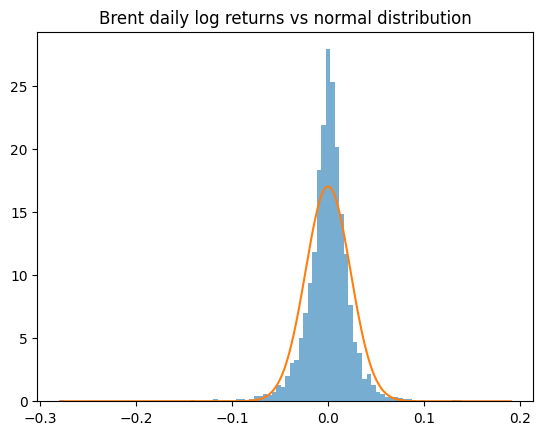

Skewness: -0.947077257483574
Excess kurtosis: 14.553852264960994


In [4]:
import scipy.stats as st

plt.hist(returns, bins=100, density=True, alpha=0.6)
x = np.linspace(returns.min(), returns.max(), 500)
plt.plot(x, st.norm.pdf(x, returns.mean(), returns.std()))
plt.title("Brent daily log returns vs normal distribution")
# plt.savefig("returns_vs_normal.png", dpi=150)
plt.show()

print("Skewness:", st.skew(returns))
print("Excess kurtosis:", st.kurtosis(returns))


**What the chart shows**

The real distribution of Brent log returns differs from the normal curve in two clear ways:

- **Taller, narrower peak.** Most days have very small moves, more so than a normal distribution would predict. Markets are quiet most of the time.
- **Fatter tails.** Extreme moves (the largest daily moves of roughly 14-28% in log terms, mostly in March-April 2020 and one on 1 April 2026) occur far more often than a normal curve allows. Under a normal distribution, moves that large would essentially never appear in 16 years of data.

**The two statistics back this up:**

- **Skewness ≈ -0.95.** The distribution is skewed to the left, meaning large falls are bigger and more common than large rises. Oil is prone to sudden demand or supply shocks that push prices down sharply.
- **Excess kurtosis ≈ 14.55.** A normal distribution scores 0, so this indicates extremely heavy tails.

**Why this matters for the rest of the project**
1. A normal-based VaR will be too optimistic in the tails. It assumes extreme losses are far rarer than they really are. We test this later by counting how often actual losses exceed the VaR estimate.
2. GARCH uses a Student-t distribution instead of a normal one, because the t-distribution has heavier tails and fits this data better.
3. Extreme days are not scattered randomly. They cluster in time (volatility clustering), as the rolling volatility chart showed. That is what makes volatility forecastable, and it is the core idea behind the models that follow.

## 4. Feature Engineering and Target

Exploration showed that volatility clusters: calm periods and turbulent periods tend to last. This section turns that into a prediction problem. For each day we build features (what is known today) and a target (what we want to predict, which is the volatility over the next 5 trading days).

In [5]:
data = pd.DataFrame({"ret": returns})

# What we want to predict: volatility over the NEXT 5 trading days
data["target_vol"] = returns.rolling(5).std().shift(-5)

# Inputs the model can see: only information from the past
data["vol_5d"]  = returns.rolling(5).std()
data["vol_21d"] = returns.rolling(21).std()
data["vol_63d"] = returns.rolling(63).std()
data["abs_ret"] = returns.abs()
data["ret_5d"]  = returns.rolling(5).sum()

data = data.dropna()
print(data.shape)
data.head()

(4119, 7)


,ret,target_vol,vol_5d,vol_21d,vol_63d,abs_ret,ret_5d
Date,,,,,,,
2010-04-06,0.003139,0.004219,0.009141,0.014503,0.017207,0.003139,0.059544
2010-04-07,-0.006522,0.009439,0.011727,0.014640,0.017223,0.006522,0.051668
2010-04-08,-0.009155,0.008200,0.013610,0.014721,0.017160,0.009155,0.025194
2010-04-09,0.000236,0.011921,0.012268,0.014698,0.017147,0.000236,0.009713
2010-04-12,-0.000708,0.016002,0.005072,0.014672,0.017145,0.000708,-0.013009


## 5. Train/Test Split and Baselines

Before fitting any model, this section sets up a fair way to judge them.

- **Time-based split.** Data up to 31 December 2021 is the training set the models learn from. Data from 2022 onwards is the test set, used only to judge them. The split is by date, not random, because real forecasters only ever know the past.
- **Error measures.** `score()` compares predicted and actual volatility using RMSE, which punishes large misses heavily, and MAE, which is the average size of the miss. Lower is better for both.
- **Baselines.** Two simple rules are scored on the test set: next week's volatility equals the last 5 days' volatility, or equals the last 21 days' volatility. They involve no fitting, so they act as benchmarks. Any model we build must beat them to justify its added complexity.

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

train = data.loc[:"2021-12-31"]
test  = data.loc["2022-01-01":]
print(len(train), len(test))

def score(actual, predicted, name):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    print(f"{name}: RMSE {rmse:.5f}  MAE {mae:.5f}")

score(test["target_vol"], test["vol_5d"],  "Baseline: last 5 days' vol")
score(test["target_vol"], test["vol_21d"], "Baseline: last 21 days' vol")

2924 1195
Baseline: last 5 days' vol: RMSE 0.01343  MAE 0.00932
Baseline: last 21 days' vol: RMSE 0.01160  MAE 0.00818


**Interpreting the baseline results** <br>

The 5-day baseline has an RMSE of 0.01343 and an MAE of 0.00932, meaning its volatility forecasts are typically about 1.3 percentage points off. <br>

The 21-day baseline has an RMSE of 0.01160 and an MAE of 0.00818, so it is typically about 1.2 points off. <br>

The 21-day baseline is more accurate on both measures, because five returns are a small, noisy sample while a month smooths out the noise and still adapts to changing conditions.<br>

These scores set the benchmark for the rest of the project: a model is only worth using if it beats an RMSE of 0.01160 and an MAE of 0.00818, and any model that fails to do so is not justified by its extra complexity.

## 6. GARCH(1,1) Model

### 6.1 Fitting the Model

The baselines assume volatility is simply whatever it has been recently. **GARCH** (Generalised Autoregressive Conditional Heteroskedasticity) is the standard finance model that formalises this idea. Volatility **clusters**, so large moves tend to follow large moves, and it also **mean-reverts**, so it drifts back toward a long-run average over time.

In GARCH(1,1), tomorrow's variance is a weighted mix of three things:
- a long-run baseline level (**omega**),
- yesterday's shock, i.e. the size of yesterday's squared return (**alpha**), and
- yesterday's variance estimate (**beta**).

The code makes four choices:
- Returns are multiplied by 100 so they are in percent, which helps the optimiser run reliably.
- The model is fitted on the **training period only** (up to 31 December 2021), so the test set stays unseen.
- A **Student-t** error distribution is used instead of a normal one, because the returns analysis showed fat tails.
- A constant mean is assumed, so the model focuses on how volatility changes, not on predicting the direction of returns.

In [7]:
from arch import arch_model

# GARCH works best with returns in percent
ret_pct = returns * 100

# Fit once on the training period only (no peeking at the test set)
train_ret = ret_pct.loc[:"2021-12-31"]
am = arch_model(train_ret, vol="GARCH", p=1, q=1, dist="t", mean="Constant")
res = am.fit(disp="off")
print(res.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                        Close   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5959.16
Distribution:      Standardized Student's t   AIC:                           11928.3
Method:                  Maximum Likelihood   BIC:                           11958.3
                                              No. Observations:                 2986
Date:                      Mon, Oct 12 2026   Df Residuals:                     2985
Time:                              14:42:17   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 6.2 Interpreting the Results

- **High persistence.** Alpha + beta is about 0.992, very close to 1. Volatility shocks therefore fade slowly, with a half-life of roughly 85 trading days, which fits the strong clustering seen in the rolling volatility chart.
- **Long-run volatility.** The parameters imply a long-run daily volatility of about 2.8%, or roughly 44% annualised.
- **Small alpha, large beta.** This is the typical pattern. Volatility reacts moderately to a single day's news, but today's level depends mostly on where it was yesterday.
- **Fat tails confirmed.** A nu of about 4.5 is far below what a normal distribution implies, supporting the choice of the t-distribution.
- **Statistical significance.** All of the volatility parameters (omega, alpha, beta and nu) are highly significant (p < 0.01), so the volatility dynamics are a real feature of the data rather than noise.

These parameters describe how volatility behaves in the training period. They say nothing yet about forecast accuracy, which is tested next on the unseen 2022+ data.

### 6.3 Forecasting the Test Period

The parameters estimated in 6.1 come from the training period only. To forecast 2022 onwards without letting the model learn from that data, the parameters are **fixed**, and the model is only allowed to update its variance estimate each day using that day's actual return. <br>

For every test day, GARCH produces a variance forecast for each of the next 5 days. These are averaged and converted into a daily volatility, which is directly comparable with the target (the volatility of the next 5 returns). The variances are averaged before taking the square root because variances add across days, whereas standard deviations do not. <br>

The forecasts are then lined up with the test set by date and scored against the 21-day baseline, using the same error measures as before.

In [8]:
# Re-use the training parameters, but let the model see returns up to each day
full_am = arch_model(ret_pct, vol="GARCH", p=1, q=1, dist="t", mean="Constant")
fixed = full_am.fix(res.params)

fc = fixed.forecast(horizon=5, start="2022-01-01", reindex=False)

# Average the 5 forecast variances, then convert to daily vol in decimal units
garch_vol = np.sqrt(fc.variance.mean(axis=1)) / 100
garch_vol.name = "garch_vol"

# Align with the test set and score
cmp = test.join(garch_vol, how="inner")
print(len(cmp))
score(cmp["target_vol"], cmp["garch_vol"], "GARCH(1,1)-t")
score(cmp["target_vol"], cmp["vol_21d"],   "Baseline: last 21 days' vol")

1195
GARCH(1,1)-t: RMSE 0.01094  MAE 0.00799
Baseline: last 21 days' vol: RMSE 0.01160  MAE 0.00818


**Interpreting the forecast scores**

GARCH beats the best baseline on both measures, by about 5.7% on RMSE and 2.3% on MAE, across 1,195 test days. The improvement is modest, which is realistic because recent volatility is already a strong predictor of near-future volatility. The larger gain on RMSE suggests GARCH helps most when volatility is changing quickly, since RMSE penalises large misses more heavily.

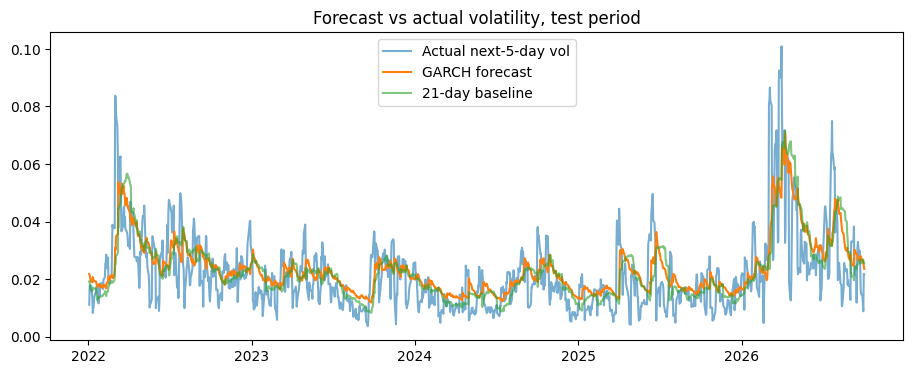

In [9]:
plt.figure(figsize=(11, 4))
plt.plot(cmp["target_vol"], label="Actual next-5-day vol", alpha=0.6)
plt.plot(cmp["garch_vol"], label="GARCH forecast")
plt.plot(cmp["vol_21d"], label="21-day baseline", alpha=0.6)
plt.legend()
plt.title("Forecast vs actual volatility, test period")
plt.savefig("forecast_vs_actual.png", dpi=150)
plt.show()

**Interpreting the chart**

The chart compares actual volatility (blue) with the GARCH forecast (orange) and the 21-day baseline (green). <br>

- **GARCH tracks the underlying level of volatility well.** Through the calm stretches between 2023 and 2025 it sits in the middle of the actual line, and it rises and falls with the broader regimes.
- **It reacts to shocks slightly faster than the rolling window.** Around the early 2022 and 2026 spikes the orange line moves up before the green one, which lags and then decays more slowly as the spike drops out of its 21-day window.
- **It underestimates the peaks.** In early 2022 actual volatility reached about 0.08 while the forecast peaked at about 0.05, and in 2026 the actual spike reached about 0.10 against a forecast of about 0.07. Like any backward-looking model, GARCH can only respond once large moves have appeared in the data, so it cannot anticipate a sudden shock. <br>

Part of the gap is also noise: the target is the standard deviation of only five returns, which is very jumpy, so no forecast can match every wiggle in the blue line.

## 7. Random Forest Model

### 7.1 Fitting and Scoring

A **random forest** is a collection of decision trees, each trained on a random sample of the data, whose predictions are averaged. Each tree asks a series of yes/no questions about the features (for example, "is the 21-day volatility above 0.02?") and ends in a prediction for that group of days. Averaging many different trees makes the result more stable than any single tree. <br>

The model uses the five features built in section 4 (`vol_5d`, `vol_21d`, `vol_63d`, `abs_ret` and `ret_5d`) to predict the volatility of the next 5 days. Its settings limit how complex it can get, so that it learns general patterns and does not memorise the training data:
- `n_estimators=300`: 300 trees.
- `max_depth=5`: each tree can ask at most 5 questions.
- `min_samples_leaf=20`: every final group must contain at least 20 days.
- `random_state=42`: makes the results reproducible. <br>

The forest is fitted on the training period only (2010 to 2021) and scored on the test period (2022 onwards), using the same error measures as the earlier models.

In [10]:
from sklearn.ensemble import RandomForestRegressor

features = ["vol_5d", "vol_21d", "vol_63d", "abs_ret", "ret_5d"]

rf = RandomForestRegressor(
    n_estimators=300, max_depth=5, min_samples_leaf=20,
    random_state=42, n_jobs=-1
)
rf.fit(train[features], train["target_vol"])
rf_pred = pd.Series(rf.predict(test[features]), index=test.index)

score(test["target_vol"], rf_pred, "Random forest")
score(cmp["target_vol"], cmp["garch_vol"], "GARCH(1,1)-t")
score(test["target_vol"], test["vol_21d"], "Baseline: last 21 days' vol")

Random forest: RMSE 0.01190  MAE 0.00812
GARCH(1,1)-t: RMSE 0.01094  MAE 0.00799
Baseline: last 21 days' vol: RMSE 0.01160  MAE 0.00818


**Interpreting the results**

The random forest beats the 5-day baseline (RMSE 0.01343) but not GARCH, and it is roughly level with the 21-day baseline: marginally better on MAE (0.00812 vs 0.00818) and slightly worse on RMSE (0.01190 vs 0.01160). The higher RMSE suggests the forest makes larger misses during volatility spikes. <br>

A likely reason is that trees can only predict averages of values they saw during training, so they cannot extrapolate. If volatility in the test period reaches levels beyond those in the training data, the forest tops out at the highest average it learned. GARCH is an equation and can extrapolate. A second reason is that the most important input, `vol_21d`, is the same quantity as the baseline, so the forest has little new information to add. <br>

The more complex machine learning model does not beat the simpler statistical one here.

### 7.2 Feature Importance

**Feature importance** shows how much each input contributed to the forest's predictions. For each feature it measures how much the trees' errors fell when that feature was used to split the data, averaged across all trees. The values add up to 1, so each can be read as a share of the total contribution. <br>

It describes which inputs the model relied on, not what causes volatility. Features that are closely related, such as the 5-day, 21-day and 63-day volatilities, also share credit with each other, which makes individual values harder to interpret.

In [11]:
print(dict(zip(features, rf.feature_importances_)))

{'vol_5d': np.float64(0.107668748946857), 'vol_21d': np.float64(0.6871949970779886), 'vol_63d': np.float64(0.08446395661614782), 'abs_ret': np.float64(0.0064276655022712185), 'ret_5d': np.float64(0.11424463185673538)}


### Interpreting the results

| Feature | Importance |
|---|---|
| `vol_21d` | 0.687 |
| `ret_5d` | 0.114 |
| `vol_5d` | 0.108 |
| `vol_63d` | 0.084 |
| `abs_ret` | 0.006 |

- **The 21-day volatility dominates,** accounting for about 69% of the total. This matches the baseline result, where the 21-day rule was the best simple predictor.
- **`ret_5d` ranks second,** which is notable because it measures the direction of the last week's move, not the size of the swings. This suggests that whether the price has been rising or falling carries information about future volatility, which is examined in section 8.
- **`abs_ret`, the size of today's move, contributes almost nothing.** Its information is largely covered by the volatility measures.

## 8. Does Direction Matter?

The feature importance in section 7 showed that `ret_5d`, the net price move over the last 5 days, was the second most useful input to the random forest. This is surprising, because it measures the direction of the move, not the size of the swings. This section checks whether future volatility really differs after price falls and price rises. <br>

All trading days are split into five equal-sized groups according to the past week's return, from "big fall" to "big rise". Within each group, the average volatility over the following 5 days is calculated, along with the median and the number of days. <br>

The mean is influenced by a few extreme periods, whereas the median describes a typical day, so showing both indicates whether a result is driven by outliers. The groups are made equal in size on purpose, so each contains about the same number of days (824, except one group with 823) and the comparison is fair.

In [12]:
data["ret_5d_bucket"] = pd.qcut(data["ret_5d"], 5, labels=["big fall", "fall", "flat", "rise", "big rise"])
print(data.groupby("ret_5d_bucket", observed=True)["target_vol"].mean())

ret_5d_bucket
big fall    0.024782
fall        0.017516
flat        0.015251
rise        0.015933
big rise    0.021765
Name: target_vol, dtype: float64


In [13]:
print(data.groupby("ret_5d_bucket", observed=True)["target_vol"].agg(["mean", "median", "count"]))

                   mean    median  count
ret_5d_bucket                           
big fall       0.024782  0.020516    824
fall           0.017516  0.015317    824
flat           0.015251  0.012901    823
rise           0.015933  0.013693    824
big rise       0.021765  0.017695    824


**Interpreting the results**

- **The pattern is a U-shape.** Volatility is lowest after quiet weeks and rises after large moves in either direction, so big moves tend to be followed by more turbulence.
- **The pattern is asymmetric.** Volatility after a big fall (0.0248) is about 14% higher than after a big rise (0.0218), and the same direction holds for ordinary falls and rises (0.0175 vs 0.0159, about 10% higher). This is known as the **leverage effect**: bad news raises volatility more than good news.
- **The mean and the median agree.** The median is lower than the mean in every group, because a few extreme periods pull the average up, but the ranking of the groups is the same, so the pattern is not driven by outliers alone. <br>

This is a description of the data, not an explanation of why it happens. It also matters for the models: a standard GARCH model treats up and down moves symmetrically, so it cannot capture this. An asymmetric version, such as GJR-GARCH, is a natural extension.

## 9. Value-at-Risk Backtest

**Value-at-Risk (VaR)** answers the question: "with 95% confidence, how much could be lost in one day?" Put the other way round, it is a loss limit that should only be exceeded on about 1 day in 20. A risk team needs this number every day, and it depends directly on how volatile the market is expected to be. <br>

For a position of £100,000, the loss limit is calculated from a model's volatility forecast:
$$
VaR = |z \times \sigma_{forecast}| \times 100{,}000, \quad z = -1.645
$$
The value -1.645 is the point on a normal curve below which 5% of outcomes fall. A higher volatility forecast gives a larger loss limit. <br>

**How the backtest works:**
1. For each day in the test period, each model's volatility forecast is turned into a loss limit.
2. The limit is compared with the **actual return on the following day**, which the forecast has not seen.
3. If the actual loss was worse than the limit, that day is a **breach**.
4. The breaches are counted for each model. <br>

A well-calibrated 95% VaR should be breached on about 5% of days, which is around 60 of the 1,195 test days. Too many breaches means the model understates risk, and too few means it is overly cautious and ties up more capital than needed. <br>

**Two simplifications to be aware of:** the forecast is a 5-day average volatility but is applied to a 1-day loss, and the -1.645 multiplier assumes returns are normally distributed even though the earlier analysis showed they have fat tails.

In [14]:
from scipy.stats import norm

conf = 0.95
z = norm.ppf(1 - conf)          # about -1.645
position = 100_000

# Forecast volatility per model, aligned on the test dates
vols = pd.DataFrame({
    "Baseline 21d": test["vol_21d"],
    "GARCH":        cmp["garch_vol"],
    "Random forest": rf_pred,
})

# Realised return on the NEXT day, so each forecast is judged on an unseen outcome
next_ret = returns.shift(-1).reindex(test.index)

results = {}
for name in vols:
    var_pct = z * vols[name]                 # negative number: the loss threshold
    breach = next_ret < var_pct
    results[name] = {
        "VaR today (£)": round(-var_pct.iloc[-1] * position),
        "Breach rate": breach.mean(),
        "Breaches": int(breach.sum()),
        "Days": int(breach.count()),
    }

print(pd.DataFrame(results).T)

               VaR today (£)  Breach rate  Breaches    Days
Baseline 21d          4191.0     0.061088      73.0  1195.0
GARCH                 3875.0     0.051046      61.0  1195.0
Random forest         3504.0     0.061088      73.0  1195.0


**Interpreting the results**

- **GARCH is the closest to the target.** Its 61 breaches are almost exactly what a well-calibrated 95% VaR should produce.
- **The baseline and the random forest breach about 22% too often.** Their loss limits are too tight, so they understate risk. They happen to produce identical breach counts.
- **The "VaR" column is a snapshot, not a performance measure.** It shows the loss limit on one date (the last day of the test period), so the differences between the models on that day say little about which is better. The breach rate over all 1,195 days is the measure that counts.
- **A lower VaR is not automatically better.** It is only useful if the breach rate still matches the target, otherwise it is simply understating risk. <br>

Whether the gaps from 5% are large enough to be statistically meaningful, or could be explained by chance, is tested in the next section.

## 10. Testing the VaR Model

Section 9 counted how often each model's loss limit was breached. This section asks whether those counts are acceptable, using two checks that look at different things: <br>
1. **How many breaches occurred.** Is the breach rate consistent with the 5% target? (the Kupiec test)
2. **When the breaches occurred.** Are they spread randomly through time, or do they bunch together? (the clustering check)

### 10.1 Kupiec Test

Seeing 73 breaches when about 60 were expected raises the question of whether the model is genuinely flawed or just unlucky. Even a perfect 95% VaR would not breach on exactly 5% of days, because the number of breaches varies from sample to sample. The **Kupiec test** is a hypothesis test that answers this. <br>

- **Null hypothesis:** the true breach probability is 5%, so the model is correctly calibrated.
- **Test statistic:** the likelihood ratio compares how likely the observed breaches are if the true rate is 5% with how likely they are at the observed rate ($\hat{p} = x/n$). If the null is true, it follows a chi-squared distribution with 1 degree of freedom:
$$
LR = -2\ln\left[\frac{(1-p)^{n-x}\,p^{x}}{(1-\hat{p})^{n-x}\,\hat{p}^{x}}\right]
$$
- **p-value:** the probability of a result at least this extreme if the model were correct. By convention, a p-value below 0.05 rejects the model.

In [15]:
from scipy.stats import chi2

def kupiec(breaches, n, p=0.05):
    x = breaches
    phat = x / n
    lr = -2 * (np.log((1-p)**(n-x) * p**x) - np.log((1-phat)**(n-x) * phat**x))
    return lr, 1 - chi2.cdf(lr, 1)

for name, b in [("Baseline", 73), ("GARCH", 61), ("Random forest", 73)]:
    lr, pval = kupiec(b, 1195)
    print(f"{name}: LR {lr:.2f}, p-value {pval:.3f}")

Baseline: LR 2.90, p-value 0.089
GARCH: LR 0.03, p-value 0.869
Random forest: LR 2.90, p-value 0.089


**Interpreting the results**

- **No model is rejected at the 5% level,** but GARCH is clearly the best calibrated: its p-value of 0.87 means its breach count is almost exactly what chance alone would produce.
- **The baseline and the random forest sit close to the line.** Their p-values of about 0.09 are just above the 0.05 cut-off, so there is some evidence that they understate risk, but not enough to reject them formally.
- **Not rejecting a model does not prove it is correct.** It only means the evidence against it is weak. With about 60 expected breaches, the test has limited power to detect modest errors.

### 10.2 Do Breaches Cluster?

The Kupiec test only counts breaches, not when they happen. A good VaR model should have breaches spread randomly through time. If breaches arrive in bunches, the model is slow to react exactly when markets turn violent, which is the worst time to be wrong. <br>

This check compares two probabilities for the GARCH model:
- the chance of a breach on the day **after a breach**, and
- the chance of a breach on the day **after a day with no breach**. <br>

If breaches are independent, the two should be about equal, and both close to 5%. A formal version of this idea is Christoffersen's independence test.

In [16]:
breach = next_ret < z * cmp["garch_vol"]
b = breach.astype(int)
print("P(breach | breach yesterday):", b[b.shift(1) == 1].mean())
print("P(breach | no breach yesterday):", b[b.shift(1) == 0].mean())

P(breach | breach yesterday): 0.06557377049180328
P(breach | no breach yesterday): 0.05030891438658429


**Interpreting the results**

The two probabilities are close, with a slight hint of clustering. However, the first figure rests on very few events: it equals 4 breaches out of 61 days that followed a breach. A change of one or two breaches would move it noticeably, so this is a weak indication, not evidence of clustering. Together with the Kupiec result, GARCH's breaches look both the right number and reasonably spread out, though with only about 60 breaches the tests cannot rule out smaller problems.

## 11. Forecasting the Next Month

The earlier sections tested the model on past data. This section uses it for its practical purpose: forecasting volatility over the **next month** (21 trading days) from the most recent data. <br>

There are two differences from the backtest:
- **The model is refitted on the full history.** The earlier forecasts used parameters from the training period only, so the test results would be fair. For a live forecast there is no reason to withhold recent data, so the latest returns are included.
- **The forecast looks 21 days ahead,** not 5, and produces one variance for each day. <br>

These daily variances are combined in three ways:
1. **Average daily volatility:** the square root of the average of the 21 variances, which describes a typical day in the coming month.
2. **Annualised volatility:** the average daily figure multiplied by $\sqrt{252}$, so it can be compared with market-quoted volatility.
3. **One-month return standard deviation:** the square root of the *sum* of the 21 variances. Variances add across days, so this measures the spread of the whole month's return:
$$
\sigma_{month} = \sqrt{\sum_{i=1}^{21} \sigma_i^2}
$$

In [17]:
# Refit on the full history for a live forecast
am_full = arch_model(ret_pct, vol="GARCH", p=1, q=1, dist="t", mean="Constant")
res_full = am_full.fit(disp="off")

fc = res_full.forecast(horizon=21)
var_path = fc.variance.iloc[-1]                 # 21 daily variances, in %²

daily_path   = np.sqrt(var_path) / 100          # volatility for each of the next 21 days
avg_daily    = np.sqrt(var_path.mean()) / 100   # average daily volatility over the month
annualised   = avg_daily * np.sqrt(252)         # in market-quoted terms
month_move   = np.sqrt(var_path.sum()) / 100    # std dev of the whole month's return

print(f"Average daily vol: {avg_daily:.2%}")
print(f"Annualised: {annualised:.1%}")
print(f"1-month return std dev: {month_move:.1%}")

Average daily vol: 2.31%
Annualised: 36.7%
1-month return std dev: 10.6%


**Interpreting the results**

- **A typical day.** Over the next month, Brent is expected to move by about 2.3% on an average day, in either direction.
- **Compared with the long run.** 36.7% annualised is below the long-run level implied by the fitted parameters (about 44%), so the model sees current conditions as calmer than average. GARCH forecasts mean-revert, so the daily path is expected to drift up toward the long-run level over the month, and the figures above are an average across that path.
- **The price range.** The monthly figure means that Brent's price change over the month has a standard deviation of about 10.6%. Roughly two-thirds of the time the move should fall within ±10.6% of the starting price. This describes the width of the range of likely outcomes and does not say which way the price will move. <br>

**Limitations of this forecast:**
- It has **not been backtested at the 21-day horizon.** The backtest in the earlier sections only covers 5-day forecasts, and longer-horizon forecasts are less informative because they lean more on the long-run average.
- The model only sees **past prices.** It cannot anticipate news such as supply disruptions or geopolitical events, so a sudden shock can push actual volatility well above this forecast.
- It is a **central estimate,** not an upper limit. As the forecast chart showed, actual volatility regularly spikes above the forecast during turbulent periods.

## 12. Conclusions

### 12.1 What the project found
Brent crude's volatility changes over time and can be forecast with reasonable success from recent price history. A GARCH(1,1) model with Student-t errors was the most accurate of the models tested. It beat the best simple baseline (the 21-day rolling volatility) by about 5.7% on RMSE and 2.3% on MAE across 1,195 unseen test days. The random forest, a more complex machine learning model, did not beat it. Its most important input was the same 21-day volatility the baseline already used, so it had little new information to add, and trees cannot predict beyond the range of volatility they saw in training.

The improvement in forecast accuracy was modest, but it carried through to risk estimation. GARCH's 95% VaR was breached on 61 days against about 60 expected (Kupiec p = 0.87), whereas the baseline and random forest were each breached on 73 days (p ≈ 0.09). Neither was formally rejected, but the pattern suggests they understate risk. There was no clear evidence that GARCH's breaches bunch together, though the check rests on only 4 events.

### 12.2 What the results do not show
- **Direction.** Volatility models measure how large price moves are likely to be, not whether prices will rise or fall. The month-ahead forecast of about 2.3% on an average day (36.7% annualised) is a statement about risk, not a trading signal.
- **Peaks.** GARCH tracked the underlying level of volatility but underestimated the sharpest spikes, such as early 2022 and 2026. A model built only on past prices cannot anticipate a sudden shock.
- **Generality.** These results apply to Brent over this period. GARCH being best here does not mean it will be best for other commodities, which would need to be tested.
- **Statistical power.** With about 60 expected breaches, the tests can only detect fairly large calibration errors, so a model that is not rejected is not proven correct.

### 12.3 Limitations
- **Futures rollover.** `BZ=F` is a continuous front-month series, so the price jumps when it moves from one contract to the next. Some of the recorded "returns" are therefore rollover effects, not real price moves, and these can inflate volatility estimates and the tails.
- **Horizon mismatch in the VaR.** The volatility forecast is a 5-day average, but it is applied to a 1-day loss.
- **Normality assumption.** The -1.645 multiplier assumes normal returns, even though Section 3.2 showed fat tails. A multiplier based on the Student-t distribution would be more consistent with the GARCH model.
- **Untested monthly forecast.** The 21-day forecast in Section 11 has not been backtested; only the 5-day horizon has.
- **Single split.** All models were judged on one train/test split, so the ranking could change under a different split or a rolling re-fit.

### 12.4 Next steps
1. Add further volatility models and compare them fairly with GARCH: EWMA, GJR-GARCH (to capture the leverage effect shown in Section 8), and a HAR-style regression.
2. Use the Student-t distribution for VaR and test a 99% confidence level, where fat tails matter most.
3. Use a rollover-adjusted price series to remove artificial jumps.
4. Backtest the 21-day forecast.
5. Repeat the analysis on other assets, such as WTI crude, natural gas or equity indices, to test whether the ranking holds.